# Query Similarity Analysis

This notebook compares the SQL queries generated by each model against the expected SQL queries.

**Similarity metrics:**
- TF-IDF + Cosine Similarity (lexical)
- Embeddings + Cosine Similarity (semantic via OpenRouter)

**Purpose:**
- Understand how close generated queries are to expected queries
- Distinguish between lexical and semantic similarity
- Identify models that use different syntax but achieve same intent

In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from openai import OpenAI
import os

# Set style (same as previous notebooks)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Color palette (same as previous notebooks)
MODEL_COLORS = {
    'ollama-duckdb-nsql': '#2E86AB',
    'ollama-llama2': '#A23B72',
    'ollama-phi3': '#F18F01',
    'openrouter-gemini-2.5-flash': '#C73E1D',
    'openrouter-gpt-5-mini': '#6A994E',
    'openrouter-gpt-oss-120b': '#BC4B51',
    'openrouter-qwen3-32b': '#8B5A3C'
}

# Paths
BASE_PATH = Path('../..')
RESULTS_PATH = BASE_PATH / 'backend' / 'logs' / 'batch-results'
TEST_SUITE_PATH = BASE_PATH / 'backend' / 'tests' / 'test-suite.json'
FIGS_PATH = BASE_PATH / 'analysis' / 'figs'
TABLES_PATH = BASE_PATH / 'analysis' / 'tables'

print("✓ Libraries imported and paths configured")

✓ Libraries imported and paths configured


## 1. Load Data

In [3]:
# Load test suite
with open(TEST_SUITE_PATH, 'r', encoding='utf-8') as f:
    test_suite = json.load(f)

# Create expected SQL mapping
expected_sql = {}
complexity_map = {}

for q in test_suite['questions']:
    expected_sql[q['id']] = q['expectedSQL']
    complexity_map[q['id']] = q['complexity']

print(f"✓ Loaded expected SQL for {len(expected_sql)} queries")

# Load all model results
def load_model_results(model_name):
    model_path = RESULTS_PATH / model_name
    results = []
    
    for i in range(1, 21):
        query_file = model_path / f'query-{i}.json'
        if query_file.exists():
            with open(query_file, 'r', encoding='utf-8') as f:
                data = json.load(f)
                results.append(data)
    
    return results

models = list(MODEL_COLORS.keys())
all_results = {}

for model in models:
    all_results[model] = load_model_results(model)
    print(f"✓ Loaded {len(all_results[model])} queries for {model}")

✓ Loaded expected SQL for 20 queries
✓ Loaded 20 queries for ollama-duckdb-nsql
✓ Loaded 20 queries for ollama-llama2
✓ Loaded 20 queries for ollama-phi3
✓ Loaded 20 queries for openrouter-gemini-2.5-flash
✓ Loaded 20 queries for openrouter-gpt-5-mini
✓ Loaded 20 queries for openrouter-gpt-oss-120b
✓ Loaded 20 queries for openrouter-qwen3-32b


## 2. TF-IDF Similarity Function

In [4]:
def tfidf_similarity(text1: str, text2: str) -> float:
    """Calculate TF-IDF cosine similarity between two SQL queries."""
    if not text1 or not text2:
        return 0.0
    
    try:
        # Normalize: lowercase and remove extra whitespace
        text1 = ' '.join(text1.lower().split())
        text2 = ' '.join(text2.lower().split())
        
        vectorizer = TfidfVectorizer()
        vectors = vectorizer.fit_transform([text1, text2])
        similarity = cosine_similarity(vectors[0:1], vectors[1:2])
        return float(similarity[0][0])
    except Exception as e:
        print(f"Error in TF-IDF similarity: {e}")
        return 0.0

# Test the function
test_sql1 = "SELECT name, email FROM customers WHERE country = 'Japan'"
test_sql2 = "SELECT name, email FROM customers WHERE country = 'Japan' ORDER BY name"
test_similarity = tfidf_similarity(test_sql1, test_sql2)
print(f"✓ TF-IDF function defined (test similarity: {test_similarity:.4f})")

✓ TF-IDF function defined (test similarity: 0.8229)


## 3. Embedding Similarity Function

**Note:** This uses OpenRouter API and will incur costs. Make sure you have set the `OPENROUTER_API_KEY` environment variable.

In [7]:
# Initialize OpenRouter client
# Load environment variables from .env file
from dotenv import load_dotenv

# Load .env from project root
env_path = BASE_PATH / '.env'
load_dotenv(env_path)

api_key = os.getenv('OPENROUTER_API_KEY')

if not api_key:
    print("⚠️  WARNING: OPENROUTER_API_KEY not found in environment variables")
    print("    Embedding similarity will be skipped. Set the key to enable this feature.")
    print(f"    Create a .env file at: {env_path}")
    print("    With content: OPENROUTER_API_KEY=sk-or-v1-your-key-here")
    USE_EMBEDDINGS = False
else:
    client = OpenAI(
        base_url="https://openrouter.ai/api/v1",
        api_key=api_key,
    )
    USE_EMBEDDINGS = True
    print("✓ OpenRouter client initialized")

def embedding_similarity(text1: str, text2: str) -> float:
    """Generate embeddings via OpenRouter and calculate cosine similarity."""
    if not USE_EMBEDDINGS:
        return None
    
    if not text1 or not text2:
        return 0.0
    
    try:
        # Normalize: lowercase and remove extra whitespace
        text1 = ' '.join(text1.lower().split())
        text2 = ' '.join(text2.lower().split())
        
        response = client.embeddings.create(
            model="openai/text-embedding-3-large",
            input=[text1, text2],
            encoding_format="float",
            extra_headers={
                'HTTP-Referer': 'https://github.com/marcelomrad/tp-bda',
                'X-Title': 'LLM SQL Evaluation System',
            },
        )
        
        e1 = np.array(response.data[0].embedding)
        e2 = np.array(response.data[1].embedding)
        
        similarity = np.dot(e1, e2) / (np.linalg.norm(e1) * np.linalg.norm(e2))
        return float(similarity)
    except Exception as e:
        print(f"Error in embedding similarity: {e}")
        return 0.0

# Test the function if embeddings are enabled
if USE_EMBEDDINGS:
    test_emb_similarity = embedding_similarity(test_sql1, test_sql2)
    print(f"✓ Embedding function defined (test similarity: {test_emb_similarity:.4f})")
else:
    print("⚠️  Embedding function skipped (API key not set)")

✓ OpenRouter client initialized
✓ Embedding function defined (test similarity: 0.9582)
✓ Embedding function defined (test similarity: 0.9582)


## 4. Calculate Similarities for All Queries

In [8]:
# Calculate similarities
similarity_results = []

for model, queries in all_results.items():
    print(f"\nProcessing {model}...")
    
    for i, query in enumerate(queries):
        question_id = query['questionId']
        generated = query.get('generatedSQL', '')
        expected = expected_sql.get(question_id, '')
        
        # TF-IDF similarity
        tfidf_sim = tfidf_similarity(generated, expected)
        
        # Embedding similarity (if enabled)
        emb_sim = None
        if USE_EMBEDDINGS:
            emb_sim = embedding_similarity(generated, expected)
            if (i + 1) % 5 == 0:
                print(f"  Processed {i + 1}/20 queries...")
        
        similarity_results.append({
            'model': model,
            'questionId': question_id,
            'complexity': complexity_map.get(question_id, 'unknown'),
            'tfidf_similarity': tfidf_sim,
            'embedding_similarity': emb_sim,
            'generatedSQL': generated,
            'expectedSQL': expected
        })
    
    print(f"  ✓ Completed {model}")

sim_df = pd.DataFrame(similarity_results)
print(f"\n✓ Created similarity DataFrame with {len(sim_df)} rows")
sim_df.head()


Processing ollama-duckdb-nsql...
  Processed 5/20 queries...
  Processed 5/20 queries...
  Processed 10/20 queries...
  Processed 10/20 queries...
  Processed 15/20 queries...
  Processed 15/20 queries...
  Processed 20/20 queries...
  ✓ Completed ollama-duckdb-nsql

Processing ollama-llama2...
  Processed 20/20 queries...
  ✓ Completed ollama-duckdb-nsql

Processing ollama-llama2...
  Processed 5/20 queries...
  Processed 5/20 queries...
  Processed 10/20 queries...
  Processed 10/20 queries...
  Processed 15/20 queries...
  Processed 15/20 queries...
  Processed 20/20 queries...
  ✓ Completed ollama-llama2

Processing ollama-phi3...
  Processed 20/20 queries...
  ✓ Completed ollama-llama2

Processing ollama-phi3...
  Processed 5/20 queries...
  Processed 5/20 queries...
  Processed 10/20 queries...
  Processed 10/20 queries...
  Processed 15/20 queries...
  Processed 15/20 queries...
  Processed 20/20 queries...
  ✓ Completed ollama-phi3

Processing openrouter-gemini-2.5-flash...
  

,model,questionId,complexity,tfidf_similarity,embedding_similarity,generatedSQL,expectedSQL
0,ollama-duckdb-nsql,1,simple,0.810541,0.956142,"SELECT name, email, city FROM customers WHERE ...","SELECT name, email, city FROM customers WHERE ..."
1,ollama-duckdb-nsql,2,simple,0.850520,0.969374,"SELECT name, price FROM products WHERE is_avai...","SELECT name, price FROM products WHERE is_avai..."
2,ollama-duckdb-nsql,3,simple,0.755791,0.928654,"SELECT supplier_id, name, contact_name, email ...","SELECT name, contact_name, email FROM supplier..."
3,ollama-duckdb-nsql,4,simple,0.799583,0.953862,"SELECT order_id, customer_id, total_amount, or...","SELECT order_id, customer_id, total_amount, or..."
4,ollama-duckdb-nsql,5,simple,0.762056,0.874929,"SELECT name, price FROM products WHERE categor...","SELECT p.name, p.price FROM products p JOIN ca..."


## 5. Overall Similarity Statistics

In [9]:
# Calculate overall statistics by model
if USE_EMBEDDINGS:
    sim_stats = sim_df.groupby('model').agg({
        'tfidf_similarity': ['mean', 'std', 'min', 'max'],
        'embedding_similarity': ['mean', 'std', 'min', 'max']
    }).round(4)
else:
    sim_stats = sim_df.groupby('model').agg({
        'tfidf_similarity': ['mean', 'std', 'min', 'max']
    }).round(4)

sim_stats.to_csv(TABLES_PATH / 'query_similarity_stats.csv')
print("✓ Saved similarity statistics table")

sim_stats

✓ Saved similarity statistics table


tfidf_similarity                          \
                                        mean     std     min     max   
model                                                                  
ollama-duckdb-nsql                    0.6943  0.1778  0.4334  0.9720   
ollama-llama2                         0.5593  0.1863  0.2536  0.8624   
ollama-phi3                           0.5173  0.1808  0.0630  0.8461   
openrouter-gemini-2.5-flash           0.7462  0.1223  0.5139  0.9417   
openrouter-gpt-5-mini                 0.7424  0.1485  0.5002  1.0000   
openrouter-gpt-oss-120b               0.8231  0.1222  0.5863  1.0000   
openrouter-qwen3-32b                  0.7718  0.1198  0.4571  0.9773   

                            embedding_similarity                          
                                            mean     std     min     max  
model                                                                     
ollama-duckdb-nsql                        0.8907  0.0768  0.7471  0.9882  
ollama-llama2                             0.8481  0.0688  0.6564  0.9453  
ollama-phi3                               0.7932  0.0956  0.6048  0.9465  
openrouter-gemini-2.5-flash               0.9336  0.0376  0.8480  0.9809  
openrouter-gpt-5-mini                     0.9173  0.0603  0.7962  1.0000  
openrouter-gpt-oss-120b                   0.9407  0.0331  0.8868  1.0000  
openrouter-qwen3-32b                      0.9157  0.0577  0.7184  0.9821

## 6. Visualizations: TF-IDF Similarity

C:\Users\user\AppData\Local\Temp\ipykernel_7624\2206230794.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(box_data, labels=models, patch_artist=True, vert=False)


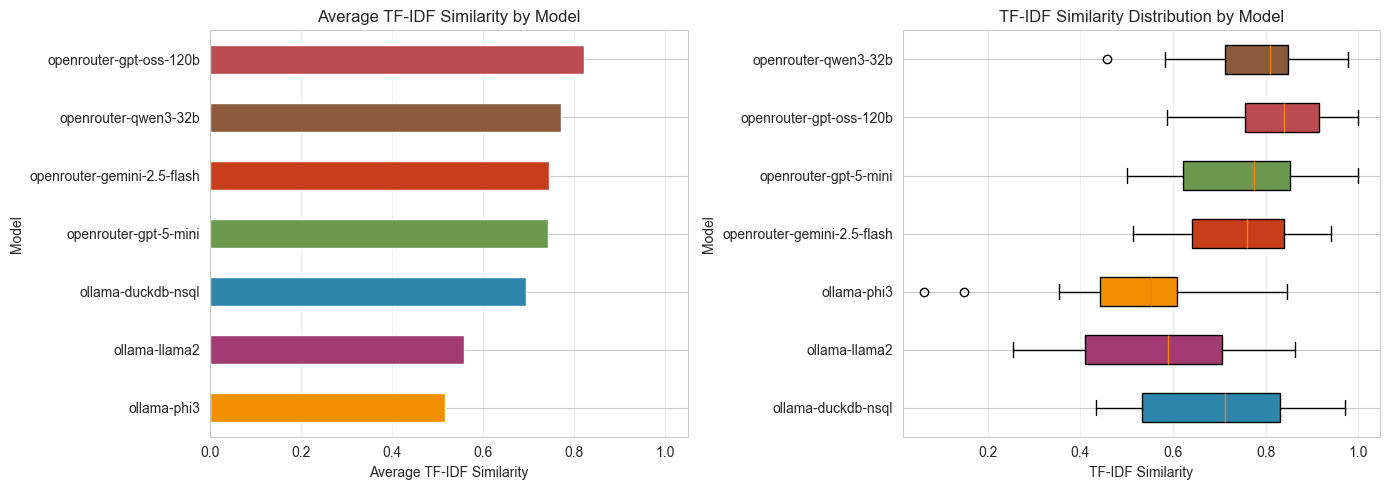

✓ Saved TF-IDF similarity visualization


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average TF-IDF similarity
tfidf_data = sim_df.groupby('model')['tfidf_similarity'].mean().sort_values(ascending=True)
colors_tfidf = [MODEL_COLORS[m] for m in tfidf_data.index]
tfidf_data.plot(kind='barh', ax=axes[0], color=colors_tfidf)
axes[0].set_xlabel('Average TF-IDF Similarity')
axes[0].set_ylabel('Model')
axes[0].set_title('Average TF-IDF Similarity by Model')
axes[0].set_xlim(0, 1.05)
axes[0].grid(axis='x', alpha=0.3)

# Box plot of TF-IDF similarity distribution
sim_df_sorted = sim_df.sort_values('model')
box_data = [sim_df_sorted[sim_df_sorted['model'] == m]['tfidf_similarity'].values for m in models]
bp = axes[1].boxplot(box_data, labels=models, patch_artist=True, vert=False)

# Color the boxes
for patch, model in zip(bp['boxes'], models):
    patch.set_facecolor(MODEL_COLORS[model])

axes[1].set_xlabel('TF-IDF Similarity')
axes[1].set_ylabel('Model')
axes[1].set_title('TF-IDF Similarity Distribution by Model')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS_PATH / 'tfidf_similarity.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved TF-IDF similarity visualization")

## 7. Visualizations: Embedding Similarity

C:\Users\user\AppData\Local\Temp\ipykernel_7624\2409202117.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp_emb = axes[1].boxplot(box_data_emb, labels=models, patch_artist=True, vert=False)


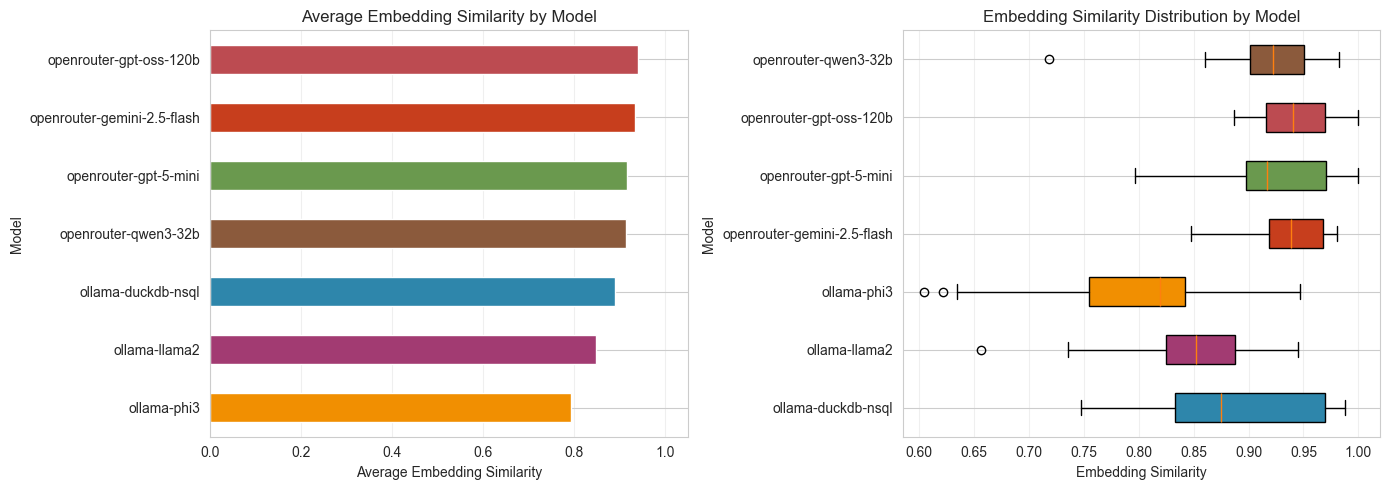

✓ Saved embedding similarity visualization


In [11]:
if USE_EMBEDDINGS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Average embedding similarity
    emb_data = sim_df.groupby('model')['embedding_similarity'].mean().sort_values(ascending=True)
    colors_emb = [MODEL_COLORS[m] for m in emb_data.index]
    emb_data.plot(kind='barh', ax=axes[0], color=colors_emb)
    axes[0].set_xlabel('Average Embedding Similarity')
    axes[0].set_ylabel('Model')
    axes[0].set_title('Average Embedding Similarity by Model')
    axes[0].set_xlim(0, 1.05)
    axes[0].grid(axis='x', alpha=0.3)
    
    # Box plot of embedding similarity distribution
    box_data_emb = [sim_df_sorted[sim_df_sorted['model'] == m]['embedding_similarity'].values for m in models]
    bp_emb = axes[1].boxplot(box_data_emb, labels=models, patch_artist=True, vert=False)
    
    # Color the boxes
    for patch, model in zip(bp_emb['boxes'], models):
        patch.set_facecolor(MODEL_COLORS[model])
    
    axes[1].set_xlabel('Embedding Similarity')
    axes[1].set_ylabel('Model')
    axes[1].set_title('Embedding Similarity Distribution by Model')
    axes[1].grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(FIGS_PATH / 'embedding_similarity.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("✓ Saved embedding similarity visualization")
else:
    print("⚠️  Skipped embedding similarity visualization (API key not set)")

## 8. Comparison: TF-IDF vs Embeddings

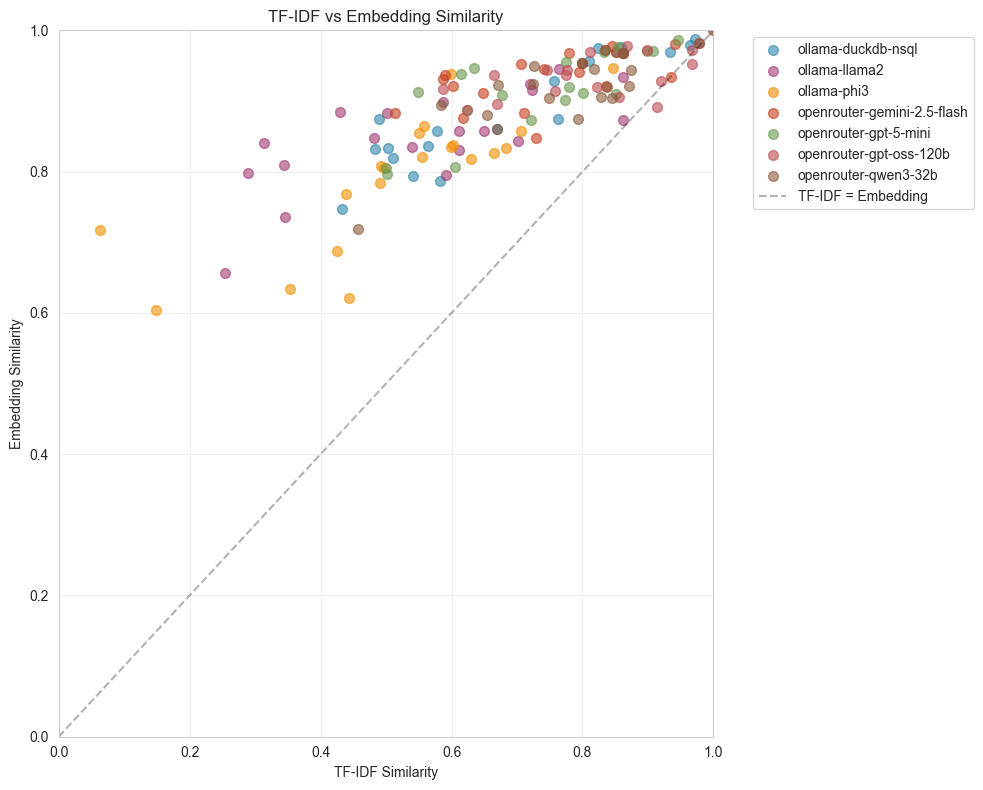

✓ Saved TF-IDF vs embedding comparison

Correlation between TF-IDF and embedding similarity: 0.8333


In [12]:
if USE_EMBEDDINGS:
    # Scatter plot comparing both metrics
    fig, ax = plt.subplots(figsize=(10, 8))
    
    for model in models:
        model_data = sim_df[sim_df['model'] == model]
        ax.scatter(
            model_data['tfidf_similarity'],
            model_data['embedding_similarity'],
            label=model,
            color=MODEL_COLORS[model],
            alpha=0.6,
            s=50
        )
    
    # Add diagonal line
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='TF-IDF = Embedding')
    
    ax.set_xlabel('TF-IDF Similarity')
    ax.set_ylabel('Embedding Similarity')
    ax.set_title('TF-IDF vs Embedding Similarity')
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(alpha=0.3)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    
    plt.tight_layout()
    plt.savefig(FIGS_PATH / 'tfidf_vs_embedding.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("✓ Saved TF-IDF vs embedding comparison")
    
    # Calculate correlation
    correlation = sim_df[['tfidf_similarity', 'embedding_similarity']].corr().iloc[0, 1]
    print(f"\nCorrelation between TF-IDF and embedding similarity: {correlation:.4f}")
else:
    print("⚠️  Skipped TF-IDF vs embedding comparison (API key not set)")

## 9. Similarity by Complexity

In [13]:
# Statistics by complexity
if USE_EMBEDDINGS:
    complexity_sim = sim_df.groupby(['model', 'complexity']).agg({
        'tfidf_similarity': 'mean',
        'embedding_similarity': 'mean'
    }).round(4)
else:
    complexity_sim = sim_df.groupby(['model', 'complexity']).agg({
        'tfidf_similarity': 'mean'
    }).round(4)

complexity_sim.to_csv(TABLES_PATH / 'similarity_by_complexity.csv')
print("✓ Saved similarity by complexity table")

complexity_sim

✓ Saved similarity by complexity table


tfidf_similarity  embedding_similarity
model                       complexity                                        
ollama-duckdb-nsql          complex               0.6361                0.8777
                            moderate              0.6818                0.8734
                            simple                0.7957                0.9366
ollama-llama2               complex               0.4978                0.8168
                            moderate              0.6213                0.8732
                            simple                0.5463                0.8519
ollama-phi3                 complex               0.5482                0.8429
                            moderate              0.5524                0.8007
                            simple                0.4178                0.7117
openrouter-gemini-2.5-flash complex               0.6478                0.9274
                            moderate              0.7992                0.9256
                            simple                0.7990                0.9549
openrouter-gpt-5-mini       complex               0.6796                0.9144
                            moderate              0.7148                0.9047
                            simple                0.8744                0.9416
openrouter-gpt-oss-120b     complex               0.7335                0.9315
                            moderate              0.8776                0.9496
                            simple                0.8614                0.9395
openrouter-qwen3-32b        complex               0.7785                0.9285
                            moderate              0.7316                0.8927
                            simple                0.8266                0.9347

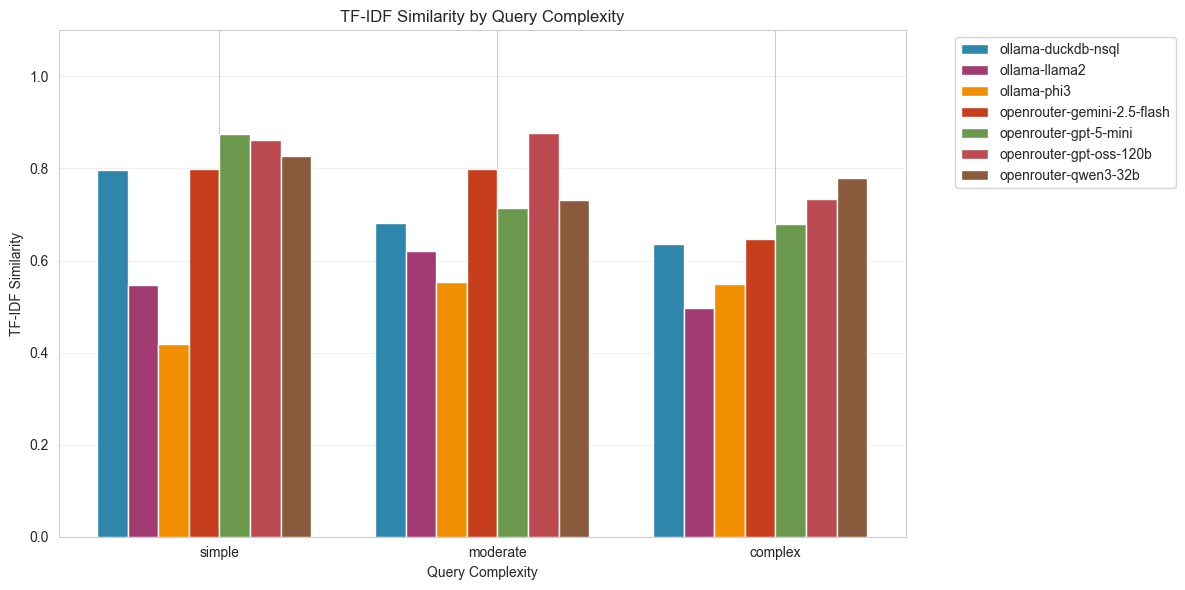

✓ Saved TF-IDF by complexity visualization


In [14]:
# Visualize TF-IDF similarity by complexity
complexity_order = ['simple', 'moderate', 'complex']
pivot_tfidf = sim_df.pivot_table(
    values='tfidf_similarity',
    index='complexity',
    columns='model',
    aggfunc='mean'
)

pivot_tfidf = pivot_tfidf.reindex(complexity_order)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(complexity_order))
width = 0.11

for i, model in enumerate(models):
    offset = (i - len(models)/2) * width
    values = pivot_tfidf[model].values
    ax.bar(x + offset, values, width, label=model, color=MODEL_COLORS[model])

ax.set_xlabel('Query Complexity')
ax.set_ylabel('TF-IDF Similarity')
ax.set_title('TF-IDF Similarity by Query Complexity')
ax.set_xticks(x)
ax.set_xticklabels(complexity_order)
ax.set_ylim(0, 1.1)
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(FIGS_PATH / 'tfidf_by_complexity.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Saved TF-IDF by complexity visualization")

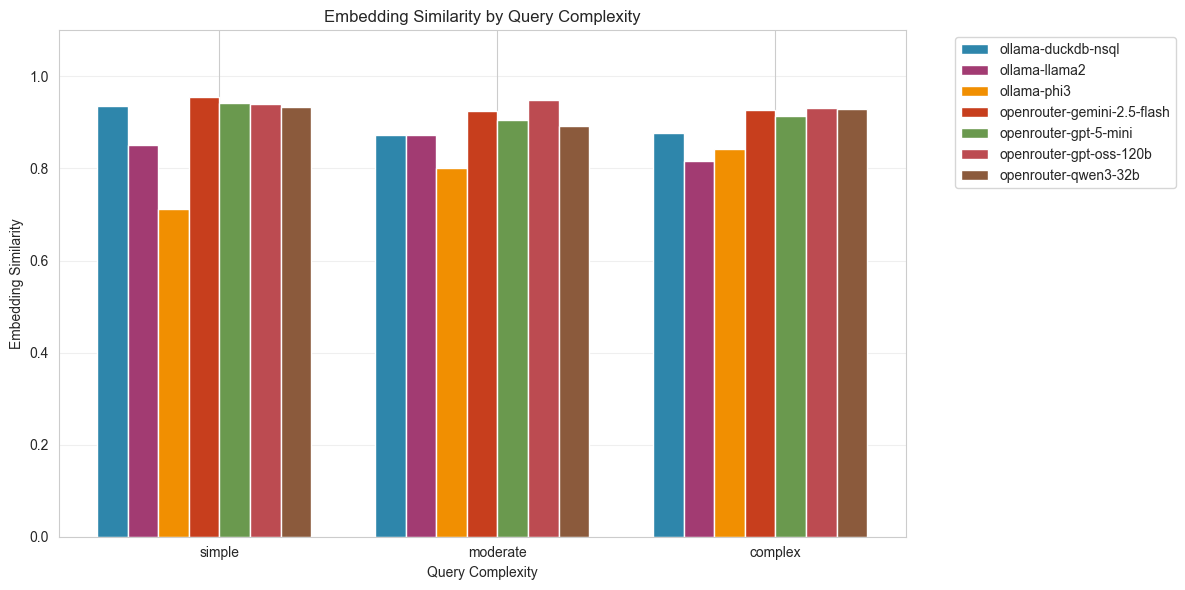

✓ Saved embedding by complexity visualization


In [15]:
if USE_EMBEDDINGS:
    # Visualize embedding similarity by complexity
    pivot_emb = sim_df.pivot_table(
        values='embedding_similarity',
        index='complexity',
        columns='model',
        aggfunc='mean'
    )
    
    pivot_emb = pivot_emb.reindex(complexity_order)
    
    fig, ax = plt.subplots(figsize=(12, 6))
    
    for i, model in enumerate(models):
        offset = (i - len(models)/2) * width
        values = pivot_emb[model].values
        ax.bar(x + offset, values, width, label=model, color=MODEL_COLORS[model])
    
    ax.set_xlabel('Query Complexity')
    ax.set_ylabel('Embedding Similarity')
    ax.set_title('Embedding Similarity by Query Complexity')
    ax.set_xticks(x)
    ax.set_xticklabels(complexity_order)
    ax.set_ylim(0, 1.1)
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(FIGS_PATH / 'embedding_by_complexity.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("✓ Saved embedding by complexity visualization")
else:
    print("⚠️  Skipped embedding by complexity visualization (API key not set)")

## 10. Examples: High vs Low Similarity

In [16]:
# Find examples of high and low similarity
print("=== HIGH TF-IDF SIMILARITY EXAMPLES ===")
high_sim = sim_df.nlargest(3, 'tfidf_similarity')[['model', 'questionId', 'tfidf_similarity', 'generatedSQL', 'expectedSQL']]
for idx, row in high_sim.iterrows():
    print(f"\nModel: {row['model']}, Query: {row['questionId']}, Similarity: {row['tfidf_similarity']:.4f}")
    print(f"Generated: {row['generatedSQL'][:100]}...")
    print(f"Expected:  {row['expectedSQL'][:100]}...")

print("\n" + "="*80)
print("=== LOW TF-IDF SIMILARITY EXAMPLES ===")
low_sim = sim_df.nsmallest(3, 'tfidf_similarity')[['model', 'questionId', 'tfidf_similarity', 'generatedSQL', 'expectedSQL']]
for idx, row in low_sim.iterrows():
    print(f"\nModel: {row['model']}, Query: {row['questionId']}, Similarity: {row['tfidf_similarity']:.4f}")
    print(f"Generated: {row['generatedSQL'][:100]}...")
    print(f"Expected:  {row['expectedSQL'][:100]}...")

=== HIGH TF-IDF SIMILARITY EXAMPLES ===

Model: openrouter-gpt-5-mini, Query: 3, Similarity: 1.0000
Generated: SELECT name, contact_name, email FROM suppliers WHERE country = 'Brazil' ORDER BY name;...
Expected:  SELECT name, contact_name, email FROM suppliers WHERE country = 'Brazil' ORDER BY name;...

Model: openrouter-gpt-oss-120b, Query: 3, Similarity: 1.0000
Generated: SELECT name, contact_name, email FROM suppliers WHERE country = 'Brazil' ORDER BY name;...
Expected:  SELECT name, contact_name, email FROM suppliers WHERE country = 'Brazil' ORDER BY name;...

Model: openrouter-gpt-oss-120b, Query: 7, Similarity: 0.9773
Generated: SELECT c.name, c.email, ROUND(SUM(o.total_amount), 3) AS total_spent FROM customers c JOIN orders o ...
Expected:  SELECT c.name, c.email, SUM(o.total_amount) as total_spent FROM customers c JOIN orders o ON c.custo...

=== LOW TF-IDF SIMILARITY EXAMPLES ===

Model: ollama-phi3, Query: 15, Similarity: 0.0630
Generated: WITH customer_orders AS ( SELECT c.c

## 11. Key Findings

### TF-IDF Similarity (Lexical)
- Measures how similar the SQL text is at a keyword/token level
- High similarity means the model uses similar SQL syntax and structure
- Lower similarity can indicate alternative valid approaches

### Embedding Similarity (Semantic)
- Measures semantic meaning, regardless of exact wording
- Can be higher than TF-IDF when queries use different syntax but same logic
- Better at identifying functionally equivalent queries

### Lexical vs Semantic Gap
- Queries where embedding > TF-IDF: Different syntax, same meaning
- Queries where TF-IDF ≈ embedding: Models closely follow expected syntax
- This gap helps identify models that "think differently" but correctly

### Complexity Impact
- Simple queries: High similarity across both metrics (standard patterns)
- Complex queries: Lower similarity, more variation in approach
- Some models maintain consistency better than others

### Model Patterns
- Some models are more "creative" (lower TF-IDF, comparable embedding)
- Others closely follow SQL conventions (high TF-IDF)
- Embedding similarity often correlates with result quality

## 12. Export Results

In [17]:
# Export detailed results
export_cols = ['model', 'questionId', 'complexity', 'tfidf_similarity']
if USE_EMBEDDINGS:
    export_cols.append('embedding_similarity')

sim_df[export_cols].to_csv(TABLES_PATH / 'detailed_similarity_results.csv', index=False)
print("✓ Saved detailed similarity results")

print("\n" + "="*60)
print("QUERY SIMILARITY ANALYSIS COMPLETE")
print("="*60)
print(f"Figures saved to: {FIGS_PATH}")
print(f"Tables saved to: {TABLES_PATH}")

if not USE_EMBEDDINGS:
    print("\n⚠️  Note: Embedding analysis was skipped.")
    print("    Set OPENROUTER_API_KEY to enable semantic similarity analysis.")

✓ Saved detailed similarity results

QUERY SIMILARITY ANALYSIS COMPLETE
Figures saved to: ..\..\analysis\figs
Tables saved to: ..\..\analysis\tables
